# Лабораторная работа 2. Word2vec, PMI и геометрия эмбеддингов (студенческая версия)

**Курс:** Методы обработки естественного языка · **Блок 1:** языковое моделирование и представления слов

**Цель.** Реализовать skip-gram with negative sampling (SGNS) с ручным выводом градиентов и экспериментально проверить, что SGNS неявно факторизует сдвинутую матрицу PMI (Levy & Goldberg, 2014).

**Что нужно сдать:**
1. SGNS с ручными градиентами, прошедший проверку градиентов (autograd и конечные разности).
2. Эмбеддинги SVD(PPMI).
3. Сравнение двух моделей на SimLex-999, MEN и аналогиях.
4. Численную проверку теоремы Леви–Голдберга.
5. Анализ анизотропии пространства и эффекта центрирования.

**Теория.** Для пары «центральное слово $w$ — контекст $c$» с $k$ негативными примерами $c_N \sim P_n$:
$$
\ell(w, c) = -\log\sigma(\mathbf{w}^\top \mathbf{c}) - \sum_{n=1}^{k}\log\sigma(-\mathbf{w}^\top \mathbf{c}_{N_n}).
$$
Если размерность эмбеддингов достаточна, чтобы каждое произведение $x = \mathbf{w}^\top\mathbf{c}$ оптимизировалось независимо, оптимум ожидаемой функции потерь достигается при
$$
\mathbf{w}^\top \mathbf{c} = \log\frac{\#(w,c)}{\#(w)\, P_n(c)} - \log k ,
$$
то есть при сдвинутой (на $\log k$) PMI относительно распределения негативов.

In [1]:
# ==== Общая настройка (одинакова во всех работах) ====
import os, math, time, json, random, pathlib, urllib.request
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

FAST_DEV_RUN = True          # True — сокращённый прогон (CPU, минуты); False — полный эксперимент
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
ARTIFACTS = pathlib.Path("artifacts"); ARTIFACTS.mkdir(exist_ok=True)
DATA = pathlib.Path("data"); DATA.mkdir(exist_ok=True)

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed()

def download(url, name):
    path = DATA / name
    if not path.exists():
        urllib.request.urlretrieve(url, path)
    return path

def load_shakespeare():
    url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
    return download(url, "shakespeare.txt").read_text(encoding="utf-8")

def load_russian():
    """Русский корпус: «Война и мир» (Л. Н. Толстой), т. 1, из открытого репозитория.
    При недоступности сети используется встроенный фрагмент."""
    urls = ["https://raw.githubusercontent.com/mmcdermott/nlp-war-and-peace/master/data/war_and_peace_ru.txt",
            "https://raw.githubusercontent.com/nevmenandr/word2vec-russian-novels/master/books_before/WarAndPeace.txt"]
    for i, u in enumerate(urls):
        try:
            t = download(u, f"ru_{i}.txt").read_text(encoding="utf-8", errors="ignore")
            if len(t) > 100_000: return t
        except Exception:
            pass
    base = ("Все счастливые семьи похожи друг на друга, каждая несчастливая семья несчастлива по-своему. "
            "Всё смешалось в доме Облонских. Жена узнала, что муж был в связи с бывшею в их доме француженкою-гувернанткой, "
            "и объявила мужу, что не может жить с ним в одном доме. ")
    return base * 400

print(f"torch {torch.__version__}, device={DEVICE}, FAST_DEV_RUN={FAST_DEV_RUN}")

torch 2.8.0.dev20250625+cu128, device=cuda, FAST_DEV_RUN=True


## 0. Корпус text8 и словарь

In [2]:
import zipfile
from collections import Counter

zpath = download("http://mattmahoney.net/dc/text8.zip", "text8.zip")
with zipfile.ZipFile(zpath) as z:
    raw = z.read("text8").decode("utf-8")
N_CHARS = 10_000_000 if FAST_DEV_RUN else 100_000_000
tokens = raw[:N_CHARS].split()
MIN_COUNT, MAX_VOCAB = 5, (10_000 if FAST_DEV_RUN else 50_000)
freq = Counter(tokens)
itos = [w for w, c in freq.most_common(MAX_VOCAB) if c >= MIN_COUNT]
stoi = {w: i for i, w in enumerate(itos)}
V = len(itos)
corpus = np.array([stoi[t] for t in tokens if t in stoi], dtype=np.int64)
counts = np.bincount(corpus, minlength=V).astype(np.float64)
print(f"токенов: {len(corpus):,}, словарь: {V:,}")

токенов: 1,552,964, словарь: 10,000


## 1. Обучающие пары и распределение негативов

- Окно фиксированной ширины `WINDOW` (без динамического сужения, чтобы проверка теоремы была точной).
- Распределение негативов $P_n(c) \propto \#(c)^{0.75}$.
- Subsampling частых слов можно включить для основного эксперимента, но для проверки теоремы его нужно отключить: теорема говорит о тех парах, на которых реально идёт обучение.

In [3]:
WINDOW, K_NEG, DIM = 4, 5, 100

def make_pairs(corpus, window):
    """Все пары (центр, контекст) на расстоянии 1..window в обе стороны."""
    centers = []
    contexts = []

    for d in range(1, window + 1):
        # Контекст справа
        centers.append(corpus[:-d])
        contexts.append(corpus[d:])

        # Контекст слева
        centers.append(corpus[d:])
        contexts.append(corpus[:-d])

    centers = np.concatenate(centers)
    contexts = np.concatenate(contexts)

    return centers, contexts
        


centers, contexts = make_pairs(corpus, WINDOW)
neg_probs = counts ** 0.75; neg_probs /= neg_probs.sum()
print(f"пар: {len(centers):,}")

пар: 12,423,692


## 2. Градиенты SGNS

Обозначим $s_+ = \sigma(\mathbf{w}^\top\mathbf{c}_+)$, $s_n = \sigma(\mathbf{w}^\top\mathbf{c}_{N_n})$. Выведите и реализуйте:
$$
\frac{\partial \ell}{\partial \mathbf{w}} = (s_+ - 1)\,\mathbf{c}_+ + \sum_n s_n \mathbf{c}_{N_n},\qquad
\frac{\partial \ell}{\partial \mathbf{c}_+} = (s_+ - 1)\,\mathbf{w},\qquad
\frac{\partial \ell}{\partial \mathbf{c}_{N_n}} = s_n\,\mathbf{w}.
$$
Функция работает с батчем и **не использует autograd**.

In [ ]:
def sgns_loss_and_grads(Wb, Cpos, Cneg):
    """Wb: (B, d) — векторы центров, Cpos: (B, d) — позитивные контексты, Cneg: (B, k, d) — негативы.
    Возвращает средний по батчу loss и градиенты (gW, gCpos, gCneg) суммарного (не среднего) loss."""
    # TODO: ваш код
    pos_logits = (Wb * Cpos).sum(dim=1)
    neg_logits = torch.einsum("bd,bkd->bk", Wb, Cneg)

    loss_per_example = -(
        F.logsigmoid(pos_logits)
        + F.logsigmoid(-neg_logits).sum(dim=1)
    )
    loss = loss_per_example.mean()

    s_pos = torch.sigmoid(pos_logits)
    s_neg = torch.sigmoid(neg_logits)

    gW = (
        (s_pos - 1)[:, None] * Cpos
        + torch.einsum("bk,bkd->bd", s_neg, Cneg)
    )

    gCpos = (s_pos - 1)[:, None] * Wb

    gCneg = s_neg[:, :, None] * Wb[:, None, :]

    return loss, gW, gCpos, gCneg

### Проверка градиентов

1. Сравните с autograd на случайном батче (в `float64`).
2. Выполните проверку конечными разностями по нескольким случайным координатам: $\frac{\ell(\theta + \varepsilon e_i) - \ell(\theta - \varepsilon e_i)}{2\varepsilon}$.

In [5]:
torch.manual_seed(0)
B, d, k = 7, 5, 3
Wb = torch.randn(B, d, dtype=torch.float64, requires_grad=True)
Cp = torch.randn(B, d, dtype=torch.float64, requires_grad=True)
Cn = torch.randn(B, k, d, dtype=torch.float64, requires_grad=True)
loss, gW, gCp, gCn = sgns_loss_and_grads(Wb.detach(), Cp.detach(), Cn.detach())
ref = -(F.logsigmoid((Wb * Cp).sum(-1)) + F.logsigmoid(-torch.einsum("bd,bkd->bk", Wb, Cn)).sum(-1)).sum()
ref.backward()
for name, a, b in [("W", gW, Wb.grad), ("Cpos", gCp, Cp.grad), ("Cneg", gCn, Cn.grad)]:
    print(name, "max |diff| =", (a - b).abs().max().item())
    assert torch.allclose(a, b, atol=1e-10)

# TODO: ваш код (проверка конечными разностями для 10 случайных координат Wb)

W max |diff| = 6.661338147750939e-16
Cpos max |diff| = 1.6653345369377348e-16
Cneg max |diff| = 2.220446049250313e-16


In [15]:
eps = 1e-6

for _ in range(10):
    i = torch.randint(B, ()).item()
    j = torch.randint(d, ()).item()

    W2 = Wb.detach().clone()
    W2[i, j] += eps
    lp = sgns_loss_and_grads(W2, Cp.detach(), Cn.detach())[0] * B

    W2[i, j] -= 2 * eps
    lm = sgns_loss_and_grads(W2, Cp.detach(), Cn.detach())[0] * B

    g_num = (lp - lm) / (2 * eps)

    print(
        f"W[{i},{j}]: "
        f"ручной={gW[i, j].item():.8f}, "
        f"численный={g_num.item():.8f}"
    )

    assert torch.allclose(g_num, gW[i, j], atol=1e-6, rtol=1e-5)

W[2,4]: ручной=0.05445210, численный=0.05445210
W[3,2]: ручной=-2.36629145, численный=-2.36629145
W[0,0]: ручной=-0.01666962, численный=-0.01666962
W[2,4]: ручной=0.05445210, численный=0.05445210
W[0,0]: ручной=-0.01666962, численный=-0.01666962
W[0,4]: ручной=-1.35639609, численный=-1.35639609
W[4,3]: ручной=0.11191630, численный=0.11191630
W[5,4]: ручной=-2.33343504, численный=-2.33343504
W[2,0]: ручной=-1.26974814, численный=-1.26974814
W[6,0]: ручной=-1.21618789, численный=-1.21618789


## 3. Обучение SGNS

Используйте разреженное обновление SGD: в батче обновляются только строки, встретившиеся в нём (`index_add_`). Learning rate линейно убывает до нуля, как в оригинальном word2vec.

обучение: 69 c


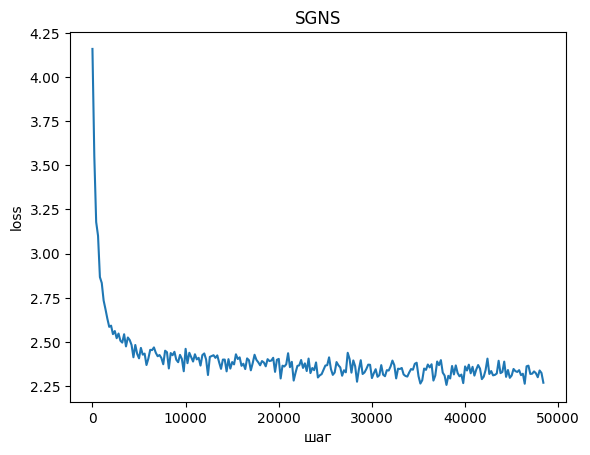

In [16]:
def train_sgns(centers, contexts, V, dim=DIM, k=K_NEG, epochs=1, batch=512, lr0=0.025, seed=SEED):
    g = torch.Generator().manual_seed(seed)
    W = (torch.rand(V, dim, generator=g) - 0.5) / dim
    C = torch.zeros(V, dim)
    neg_t = torch.tensor(neg_probs, dtype=torch.float)
    n = len(centers); steps = epochs * (n // batch); step = 0; hist = []
    cen_t, ctx_t = torch.from_numpy(centers), torch.from_numpy(contexts)
    for ep in range(epochs):
        perm = torch.randperm(n, generator=g)
        for b in range(n // batch):
            idx = perm[b * batch:(b + 1) * batch]
            wi, ci = cen_t[idx], ctx_t[idx]
            ni = torch.multinomial(neg_t, batch * k, replacement=True, generator=g).view(batch, k)
            lr = lr0 * max(1e-4, 1 - step / steps)
            # TODO: ваш код (вычислите градиенты и обновите W и C через index_add_)
            loss, gW, gCpos, gCneg = sgns_loss_and_grads(
                W[wi], C[ci], C[ni]
            )

            W.index_add_(0, wi, gW, alpha=-lr)
            C.index_add_(0, ci, gCpos, alpha=-lr)
            C.index_add_(
                0,
                ni.reshape(-1),
                gCneg.reshape(-1, dim),
                alpha=-lr,
            )
            
            if step % 200 == 0: hist.append((step, loss.item()))
            step += 1
            
    return W, C, hist

t0 = time.time()
W_sgns, C_sgns, hist = train_sgns(centers, contexts, V, epochs=2 if FAST_DEV_RUN else 5)
print(f"обучение: {time.time() - t0:.0f} c")
plt.plot(*zip(*hist)); plt.xlabel("шаг"); plt.ylabel("loss"); plt.title("SGNS"); plt.show()

## 4. PPMI и SVD

1. Постройте разреженную матрицу совместной встречаемости $\#(w,c)$ по тем же парам.
2. Вычислите PPMI со сглаживанием распределения контекстов ($\alpha = 0.75$):
   $\mathrm{PPMI}(w,c) = \max\bigl(0, \log\frac{\#(w,c)\,\sum_{c'}\#(c')^{\alpha}}{\#(w)\,\#(c)^{\alpha}}\bigr)$.
3. Усечённое SVD: $\mathrm{PPMI} \approx U_d \Sigma_d V_d^\top$, эмбеддинги $U_d \Sigma_d^{1/2}$.

In [17]:
import scipy.sparse as sp
from scipy.sparse.linalg import svds

cooc = sp.coo_matrix((np.ones(len(centers), dtype=np.float64), (centers, contexts)), shape=(V, V)).tocsr()
cooc.sum_duplicates()

def ppmi_matrix(cooc, alpha=0.75):
    C = cooc.tocoo()

    word_counts = np.asarray(
        cooc.sum(axis=1)
    ).ravel()

    context_counts = np.asarray(
        cooc.sum(axis=0)
    ).ravel()

    context_probs = context_counts ** alpha
    context_probs /= context_probs.sum()

    pmi = (
        np.log(C.data)
        - np.log(word_counts[C.row])
        - np.log(context_probs[C.col])
    )

    keep = pmi > 0

    return sp.csr_matrix(
        (
            pmi[keep],
            (C.row[keep], C.col[keep]),
        ),
        shape=cooc.shape,
    )

t0 = time.time()
P = ppmi_matrix(cooc)
U, S, Vt = svds(P, k=DIM)
W_svd = torch.tensor(U * np.sqrt(S), dtype=torch.float)
print(f"PPMI nnz={P.nnz:,}, SVD: {time.time() - t0:.0f} c")

PPMI nnz=2,428,969, SVD: 2 c


## 5. Оценка: SimLex-999, MEN, аналогии

- Сходство: ранговая корреляция Спирмена между косинусом и оценками людей (только пары, покрытые словарём; укажите покрытие).
- Аналогии: метод 3CosAdd, $\arg\max_{x}\cos(x, b - a + a^*)$, исключая слова запроса. Для каждой модели посчитайте точность по семантическим и синтаксическим разделам.

In [18]:
import re
import pandas as pd
from scipy.stats import spearmanr

base = "https://raw.githubusercontent.com/vecto-ai/word-benchmarks/master/word-similarity/monolingual/en/"
sim_sets = {name: pd.read_csv(download(base + f"{name}.csv", f"{name}.csv")) for name in ("simlex999", "men")}
analogy_lines = download("https://raw.githubusercontent.com/tmikolov/word2vec/master/questions-words.txt",
                         "questions-words.txt").read_text().splitlines()

def normed(E): return F.normalize(E, dim=1)

def eval_similarity(E, df):
    # TODO: ваш код
    En = normed(E)

    words1 = df["word1"].astype(str).str.lower()
    words2 = df["word2"].astype(str).str.lower()

    covered = (
        words1.map(lambda w: w in stoi)
        & words2.map(lambda w: w in stoi)
    )

    coverage = covered.mean()

    if covered.sum() == 0:
        return float("nan"), 0.0

    ids1 = torch.tensor(
        [stoi[w] for w in words1[covered]],
        dtype=torch.long,
    )

    ids2 = torch.tensor(
        [stoi[w] for w in words2[covered]],
        dtype=torch.long,
    )

    predicted = (
        En[ids1] * En[ids2]
    ).sum(dim=1).cpu().numpy()

    gold = df.loc[
        covered, "similarity"
    ].to_numpy(dtype=float)

    rho = spearmanr(predicted, gold).statistic

    return float(rho), float(coverage)

def eval_analogies(E, max_q=None):
    En = normed(E); section = None; res = {"semantic": [0, 0], "syntactic": [0, 0]}
    qs = []
    for line in analogy_lines:
        if line.startswith(":"):
            section = "syntactic" if line.startswith(": gram") else "semantic"; continue
        a, b, a2, b2 = line.lower().split()
        if all(w in stoi for w in (a, b, a2, b2)): qs.append((section, stoi[a], stoi[b], stoi[a2], stoi[b2]))
    if max_q: random.Random(0).shuffle(qs); qs = qs[:max_q]
    # TODO: ваш код (батчево вычислите b - a + a2, косинусы ко всем словам, исключите слова запроса)
    batch_size = 256

    for start in range(0, len(qs), batch_size):
        block = qs[start:start + batch_size]

        sections = [q[0] for q in block]
        ids = torch.tensor(
            [q[1:] for q in block],
            dtype=torch.long,
        )

        a, b, a2, b2 = ids.T

        query = En[b] - En[a] + En[a2]
        query = F.normalize(query, dim=1)

        similarities = query @ En.T

        row = torch.arange(len(block))
        similarities[row, a] = -torch.inf
        similarities[row, b] = -torch.inf
        similarities[row, a2] = -torch.inf

        predicted = similarities.argmax(dim=1)

        for section_name, pred, target in zip(
            sections,
            predicted.tolist(),
            b2.tolist(),
        ):
            res[section_name][0] += int(pred == target)
            res[section_name][1] += 1
            
    return {k: (v[0] / max(v[1], 1), v[1]) for k, v in res.items()}

rows = []
for name, E in [("SGNS (W)", W_sgns), ("SGNS (W+C)", W_sgns + C_sgns), ("SVD(PPMI)", W_svd)]:
    r = {"модель": name}
    for s, df in sim_sets.items():
        rho, cov = eval_similarity(E, df); r[s] = round(rho, 3); r[s + " покрытие"] = round(cov, 2)
    an = eval_analogies(E, max_q=3000 if FAST_DEV_RUN else None)
    r["analogy sem"] = round(an["semantic"][0], 3); r["analogy syn"] = round(an["syntactic"][0], 3)
    rows.append(r)
pd.DataFrame(rows)

,модель,simlex999,simlex999 покрытие,men,men покрытие,analogy sem,analogy syn
0,SGNS (W),0.115,0.61,NaN,0.0,0.141,0.047
1,SGNS (W+C),0.130,0.61,NaN,0.0,0.091,0.046
2,SVD(PPMI),0.073,0.61,NaN,0.0,0.415,0.137


## 6. Проверка теоремы Леви–Голдберга

Для частых пар $(w, c)$ (например, $\#(w,c) \ge 50$) сравните $\mathbf{w}^\top\mathbf{c}$ у обученной SGNS с теоретическим оптимумом
$$
\mathrm{SPMI}_k(w,c) = \log\frac{\#(w,c)}{\#(w)\,P_n(c)} - \log k.
$$
Постройте диаграмму рассеяния, посчитайте корреляцию Пирсона и Спирмена, а также среднее отклонение. Объясните, почему совпадение неполное (конечная размерность, недообученность, редкие пары).

In [ ]:
# TODO: ваш код (соберите частые пары, посчитайте SPMI и w·c, постройте scatter и корреляции)

## 7. Анизотропия

1. Посчитайте средний косинус между случайными парами слов для каждой модели.
2. Найдите долю дисперсии, объясняемую первыми 5 главными компонентами.
3. Примените «all-but-the-top» (Mu & Viswanath, 2018): вычесть среднее и проекции на первые $D$ главных компонент. Как меняется качество на SimLex и MEN?

In [ ]:
def anisotropy(E, n=20000):
    En = normed(E); i, j = torch.randint(len(E), (n,)), torch.randint(len(E), (n,))
    return (En[i] * En[j]).sum(1).mean().item()

def all_but_the_top(E, D=3):
    # TODO: ваш код
    raise NotImplementedError

for name, E in [("SGNS (W)", W_sgns), ("SVD(PPMI)", W_svd)]:
    X = E - E.mean(0); s = torch.linalg.svdvals(X) ** 2
    print(f"{name:10s} средний cos={anisotropy(E):.3f}  доля 5 ГК={(s[:5].sum() / s.sum()).item():.3f}")
    for D in (0, 1, 3, 7):
        E2 = all_but_the_top(E, D) if D else E - E.mean(0)
        print(f"   D={D}: SimLex={eval_similarity(E2, sim_sets['simlex999'])[0]:.3f}  MEN={eval_similarity(E2, sim_sets['men'])[0]:.3f}  cos={anisotropy(E2):.3f}")

## Вопросы

1. Выведите оптимум $\mathbf{w}^\top\mathbf{c}$ для SGNS из условия равенства нулю производной ожидаемой функции потерь по $x = \mathbf{w}^\top\mathbf{c}$.
2. Почему отрицательные значения PMI отбрасывают (PPMI)? Что в SGNS соответствует этому усечению?
3. Почему сглаживание $P_n(c) \propto \#(c)^{0.75}$ полезно и в SGNS, и в PPMI?
4. Чем объясняется анизотропия пространства эмбеддингов? Как она связана с частотой слов?
5. Почему SimLex-999 сложнее для дистрибутивных моделей, чем MEN?